# ADP 26회 - 출제 주제 기반 복원 연습

출처: 기출문제 모음 PDF pp.5~6: 구매 군집, 표본수·지역 비율·혈압·은 가격·Bayesian 회귀

**복원 연습 자료·예시 풀이이며 공식 정답이 아닙니다.** 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

동봉 data를 사용하며 원 질문·보완 조건·풀이를 분리합니다. 입력 파일은 UTF-8. 저장소 루트 또는 현재 회차 폴더에서 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'26회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 구매 군집 및 추천

자료: retail.csv

원문 Quantity 결측 보존한 합성 자료, KMeans/DBSCAN. 구매고객 1241 포함.

### 1-1

결측을 확인·대치하고 이상값 보정 전후 통계를 제시하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 탐색 군집 자료 전체 기준 대치·winsorization을 명시합니다. 유효 대량 주문을 이상치로 지울 수 있어 정책으로 확정하지 않습니다.

In [2]:
retail26=load('retail.csv');print(retail26.isna().sum());before=retail26.Quantity.describe();retail26.Quantity=retail26.Quantity.fillna(retail26.Quantity.median());retail26.Country=retail26.Country.fillna('Unknown');upper=retail26.Quantity.quantile(.99);retail26.Quantity=retail26.Quantity.clip(upper=upper);print(pd.DataFrame({'before':before,'after':retail26.Quantity.describe()}))

InvoiceNo        0
CustomerID       0
StockCode        0
StockCategory    0
Date             0
Quantity         1
UnitPrice        0
Country          1
dtype: int64
           before       after
count  749.000000  750.000000
mean     7.090788    5.898667
std     32.831685    3.241977
min      1.000000    1.000000
25%      3.000000    3.000000
50%      5.000000    5.000000
75%      8.000000    8.000000
max    900.000000   15.000000


### 1-2

고객별 구매 F/M을 구성하여 KMeans 및 DBSCAN 군집을 비교하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 군집 단위는 고객으로 보완합니다. 명목형 Country/StockCode의 정수 거리 사용을 피합니다.

   k  silhouette    inertia
0  2    0.545356  44.332399
1  3    0.516300  31.653463
2  4    0.435735  23.123991
3  5    0.435286  17.334131


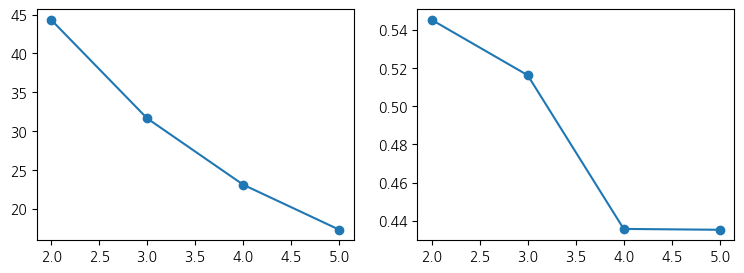

        CustomerID          F            M  clust
clust                                            
0      1225.185185   9.185185  1102.387778    0.0
1      1233.030303  15.212121  2459.947273    1.0
 1    43
 0    13
-1     4
Name: count, dtype: int64
DBSCAN -1은 잡음, 군집과 따로 해석.


In [3]:
retail26['amount']=retail26.Quantity*retail26.UnitPrice;fm26=retail26.groupby('CustomerID').agg(F=('InvoiceNo','nunique'),M=('amount','sum'))
cluster26,k26=cluster(np.log1p(fm26),OUT,original=fm26.reset_index())
z26=StandardScaler().fit_transform(np.log1p(fm26));db=DBSCAN(eps=.5,min_samples=4).fit_predict(z26);print(pd.Series(db).value_counts());print('DBSCAN -1은 잡음, 군집과 따로 해석.')

### 2-1

군집별 특성과 대표 상품을 도출하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 대표 상품 기준을 총 구매 수량으로 명시했습니다.

In [4]:
joined=retail26.merge(cluster26[['CustomerID','clust']],on='CustomerID',validate='many_to_one');print(cluster26.groupby('clust')[['F','M']].mean());representatives=joined.groupby(['clust','StockCode']).Quantity.sum().reset_index().sort_values('Quantity',ascending=False).groupby('clust').head(1);print(representatives)

               F            M
clust                        
0       9.185185  1102.387778
1      15.212121  2459.947273
   clust StockCode  Quantity
5      1        P2    1526.0
2      0        P2     517.0


### 2-2

CustomerID=1241에게 같은 군집의 미구매 인기 상품을 추천하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 이미 구매한 상품을 제외합니다. 합성 자료에서 후보가 없을 수 있으며 억지 추천을 만들지 않습니다.

In [5]:
customer=1241;row=cluster26[cluster26.CustomerID==customer];assert len(row)==1
label=row.clust.iloc[0];seen=set(retail26.loc[retail26.CustomerID==customer,'StockCode'])
recommend=joined[(joined.clust==label)&(~joined.StockCode.isin(seen))].groupby('StockCode').Quantity.sum().sort_values(ascending=False)
print(recommend.head(3));print('미구매 후보가 없으면 신규 상품/전체 인기 대체 정책이 필요합니다.')

Series([], Name: Quantity, dtype: float64)
미구매 후보가 없으면 신규 상품/전체 인기 대체 정책이 필요합니다.


## 3. 최소 표본수

자료: 데이터 없음

불량률 p=.9, 양측 95% 신뢰수준·오차한계 .05의 정규 근사, 비복원 유한모집단 보정 없음.

### 3-1

비율 오차한계 .05를 만족할 최소 표본수를 계산하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** ceil로 올림합니다. 원문 신뢰수준이 없어 95%를 보완했으며 보수적 p=.5를 쓰면 더 커집니다.

In [6]:
n_min=int(np.ceil(stats.norm.ppf(.975)**2*.9*.1/.05**2));print(n_min)

139


## 4. 지역 지지도

자료: regional_support.csv

원 PDF 자체도 수치를 임의 예시라고 명시: yes=100,200,300; no=150,130,180.

### 4-1

세 지역의 지지 비율이 같은지 chi-square 동질성 검정을 수행하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 표본 행은 지역, 열은 지지 여부. 기대도수가 작으면 근사 검정 적용을 재검토합니다.

In [7]:
support=load('regional_support.csv');chi,p,df_,expected=stats.chi2_contingency(support[['yes','no']],correction=False);print({'chi2':chi,'df':df_,'p':p,'reject':p<.05});print(expected)

{'chi2': np.float64(37.00340360122969), 'df': 2, 'p': np.float64(9.221742733277462e-09), 'reject': np.True_}
[[141.50943396 108.49056604]
 [186.79245283 143.20754717]
 [271.69811321 208.30188679]]


## 5. 남녀 혈압 평균

자료: blood_pressure.csv

독립 남16·여9 합성, 양측 Welch, 정규성 진단과 95% 평균차 CI.

### 5-1

두 집단 평균 차이를 검정하고 동일 가정의 평균차 CI와 결론을 대조하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 각 집단 평균 CI의 겹침으로 평균차 검정을 대신하지 않습니다. 같은 Welch 차이 CI에 0이 포함되는지 확인합니다.

In [8]:
blood=load('blood_pressure.csv');m=blood.loc[blood.sex=='M','value'];f=blood.loc[blood.sex=='F','value'];test_b=stats.ttest_ind(m,f,equal_var=False)
a=m.var(ddof=1)/len(m);b_=f.var(ddof=1)/len(f);se=np.sqrt(a+b_);df_=(a+b_)**2/(a*a/(len(m)-1)+b_*b_/(len(f)-1));ci=stats.t.interval(.95,df_,loc=m.mean()-f.mean(),scale=se)
print({'t':test_b.statistic,'p':test_b.pvalue,'difference_CI':ci,'reject':test_b.pvalue<.05});print(stats.shapiro(m),stats.shapiro(f));assert (ci[0]>0 or ci[1]<0)==(test_b.pvalue<.05)

{'t': np.float64(1.5770574842052278), 'p': np.float64(0.1285455281669565), 'difference_CI': (np.float64(-1.5578316527340075), np.float64(11.534540975170854)), 'reject': np.False_}
ShapiroResult(statistic=np.float64(0.9709093685879536), pvalue=np.float64(0.8531169373510075)) ShapiroResult(statistic=np.float64(0.943184781012278), pvalue=np.float64(0.6157948460306214))


## 6. 은 가격 rolling/trend

자료: silver.csv

9개월 합성. 누락 가격은 그래프·rolling에 보간, 추론은 관측된 월만 사용.

### 6-1

3개 관측 rolling 평균을 표시하고 월별 증가 추세를 검정하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 9개는 작은 시계열이라 잔차 자기상관·검정 가정에 취약합니다. 보간값을 새 독립 관측으로 추론에 넣지 않습니다.

         date      value   rolling3
0  2014-01-01  82.719026        NaN
1  2014-02-01  87.126047        NaN
2  2014-03-01  91.309070  87.051381
3  2014-04-01        NaN  90.023749
4  2014-05-01  91.963191  91.636131
5  2014-06-01  88.250222  90.616515
6  2014-07-01  80.483899  86.899104
7  2014-08-01  77.347869  82.027330
8  2014-09-01  70.194478  76.008749


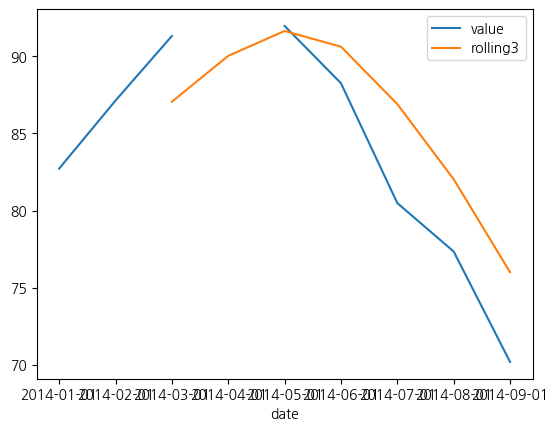

                            OLS Regression Results                            
Dep. Variable:                  value   R-squared:                       0.403
Model:                            OLS   Adj. R-squared:                  0.303
Method:                 Least Squares   F-statistic:                     4.048
Date:                Tue, 13 Oct 2026   Prob (F-statistic):             0.0909
Time:                        16:04:05   Log-Likelihood:                -24.863
No. Observations:                   8   AIC:                             53.73
Df Residuals:                       6   BIC:                             53.89
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         92.0751      4.724     19.490      0.0

In [9]:
silver=load('silver.csv');silver['rolling3']=silver.value.interpolate().rolling(3).mean();print(silver)
silver.plot(x='date',y=['value','rolling3']);plt.show();silver['month']=np.arange(1,len(silver)+1)
observed=silver.dropna(subset=['value']);trend=sm.OLS(observed.value,sm.add_constant(observed[['month']])).fit();print(trend.summary())
print('양의 추세 단측 p:',stats.t.sf(trend.tvalues['month'],trend.df_resid))

## 7. Bayesian 회귀

자료: body.csv

Weight/Height→Waist 수치. 표준화 특성, 알려진 noise SD=4, 기울기 독립 N(0,10²), 절편 N(100,10²) 사전.

### 7-1

알려진 잡음 분산의 정규 선형 모형에서 사후 계수 평균·95% credible interval을 구하고 80kg/170cm의 허리를 예측하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 절편 사전 평균=100, 나머지=0, 모두 사전 SD=10으로 자료 적합 전에 고정합니다. 잡음 SD는 연습용 알려진 값. BayesianRidge의 추정 hyperparameter와 이 고정 사전 모형은 다릅니다.

In [10]:
body=load('body.csv');scaler=StandardScaler().fit(body[['Weight','Height']]);design=np.column_stack([np.ones(len(body)),scaler.transform(body[['Weight','Height']])]);prior_mean=np.array([100.,0.,0.]);prior_precision=np.eye(3)/100;sigma2=16
cov=np.linalg.inv(prior_precision+design.T@design/sigma2);mean=cov@(prior_precision@prior_mean+design.T@body.Waist.to_numpy()/sigma2)
print(pd.DataFrame({'term':['intercept','weight_z','height_z'],'posterior_mean':mean,'low':mean-1.96*np.sqrt(np.diag(cov)),'high':mean+1.96*np.sqrt(np.diag(cov))}))
new=np.r_[1.,scaler.transform(pd.DataFrame({'Weight':[80],'Height':[170]}))[0]];point=float(new@mean);predictive_sd=np.sqrt(sigma2+new@cov@new);print({'predicted_waist':point,'posterior_predictive_95':(point-1.96*predictive_sd,point+1.96*predictive_sd)})

        term  posterior_mean        low       high
0  intercept       81.197794  80.535572  81.860017
1   weight_z        6.990846   6.325781   7.655911
2   height_z       -0.740169  -1.405233  -0.075104
{'predicted_waist': 88.58614146583841, 'posterior_predictive_95': (np.float64(80.68637455616482), np.float64(96.485908375512))}
